In [16]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [17]:
df = pd.read_csv("../data/Telco-Customer-Churn.csv")


In [18]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

In [19]:
df = df.drop(columns=["customerID"])
X = df.drop(columns=["Churn"])
y = df["Churn"].map({
    "Yes": 1,
    "No": 0
})

In [20]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("Target distribution:")
print(y.value_counts())


Features shape: (7043, 19)
Target shape: (7043,)
Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [22]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (5634, 19)
X_test: (1409, 19)
y_train: (5634,)
y_test: (1409,)


In [23]:
num_cols = X.select_dtypes(include=["int64", "float64"]).columns
cat_cols = X.select_dtypes(include=["object"]).columns


In [24]:
print("Numerical columns:")
print(list(num_cols))

print("\nCategorical columns:")
print(list(cat_cols))


Numerical columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [25]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [26]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [27]:
from sklearn.linear_model import LogisticRegression

In [28]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

In [29]:
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [30]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score
)

In [31]:
y_pred = model.predict(X_test)

y_prob = model.predict_proba(X_test)[:, 1]

In [32]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred)

recall = recall_score(y_test, y_pred)

roc_auc = roc_auc_score(y_test, y_prob)

print("Model Evaluation Results")
print("------------------------")
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("ROC-AUC:", round(roc_auc, 4))

Model Evaluation Results
------------------------
Accuracy: 0.8055
Precision: 0.6572
Recall: 0.5588
ROC-AUC: 0.8419


In [33]:
import joblib

In [34]:
# Save the complete trained pipeline

joblib.dump(model, "../models/churn_pipeline.pkl")

print("Model saved successfully!")

Model saved successfully!


# Day 2

In [36]:
print("Checking Day 1 components...")

print(X_train.shape)
print(X_test.shape)

print(y_train.shape)
print(y_test.shape)

print(preprocessor)

Checking Day 1 components...
(5634, 19)
(1409, 19)
(5634,)
(1409,)
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'Tec

In [37]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_score
)

In [38]:

# DAY 2 - Model Comparison

RANDOM_STATE = 42

# Define three candidate models
day2_candidates = {

    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE,
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=250,
        random_state=RANDOM_STATE,
        class_weight="balanced",
        n_jobs=-1
    ),

    "SVM": SVC(
        kernel="rbf",
        probability=True,
        class_weight="balanced",
        random_state=RANDOM_STATE
    )
}

print("Candidate models:", list(day2_candidates))


Candidate models: ['Decision Tree', 'Random Forest', 'SVM']


In [39]:
# DAY 2 - Cross Validation

cv_strategy = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

In [40]:
day2_cv_results = {}

for model_name, estimator in day2_candidates.items():

    candidate_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", estimator)
    ])

    scores = cross_val_score(
        candidate_pipeline,
        X_train,
        y_train,
        scoring="recall",
        cv=cv_strategy,
        n_jobs=-1
    )

    day2_cv_results[model_name] = scores

    print(f"\n{model_name}")
    print("Fold Recall:", scores)
    print("Mean Recall:", scores.mean())


Decision Tree
Fold Recall: [0.50803213 0.47389558 0.49098196]
Mean Recall: 0.4909698915904097

Random Forest
Fold Recall: [0.62248996 0.65461847 0.61923848]
Mean Recall: 0.6321156368962825

SVM
Fold Recall: [0.77309237 0.76907631 0.79559118]
Mean Recall: 0.7792532856878416


In [41]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score
)

day2_trained_models = {}
day2_test_results = {}

for model_name, estimator in day2_candidates.items():

    candidate_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", estimator)
    ])

    # Train
    candidate_pipeline.fit(X_train, y_train)

    # Predict
    y_pred = candidate_pipeline.predict(X_test)
    y_prob = candidate_pipeline.predict_proba(X_test)[:, 1]

    # Evaluate
    metrics = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    }

    day2_trained_models[model_name] = candidate_pipeline
    day2_test_results[model_name] = metrics

    print(f"\n{model_name}")
    for metric, value in metrics.items():
        print(f"{metric}: {value:.4f}")



Decision Tree
Accuracy: 0.7317
Precision: 0.4946
Recall: 0.4866
ROC-AUC: 0.6537

Random Forest
Accuracy: 0.7672
Precision: 0.5542
Recall: 0.6283
ROC-AUC: 0.8224


c:\python312\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(



SVM
Accuracy: 0.7438
Precision: 0.5115
Recall: 0.7727
ROC-AUC: 0.8211


In [42]:

import joblib
from pathlib import Path

# Load Day 1 model
baseline_model = joblib.load(
    Path("../models/churn_pipeline.pkl")
)

# Predict using Day 1 model
baseline_pred = baseline_model.predict(X_test)
baseline_prob = baseline_model.predict_proba(X_test)[:, 1]

# Calculate baseline metrics
day1_results = {
    "Accuracy": accuracy_score(y_test, baseline_pred),
    "Precision": precision_score(y_test, baseline_pred),
    "Recall": recall_score(y_test, baseline_pred),
    "ROC-AUC": roc_auc_score(y_test, baseline_prob)
}

print("Day 1 Logistic Regression")
for metric, value in day1_results.items():
    print(f"{metric}: {value:.4f}")


Day 1 Logistic Regression
Accuracy: 0.8055
Precision: 0.6572
Recall: 0.5588
ROC-AUC: 0.8419


In [43]:
comparison = {
    "Logistic Regression": day1_results,
    **day2_test_results
}

comparison_df = pd.DataFrame(comparison).T

print(comparison_df.round(4))

                     Accuracy  Precision  Recall  ROC-AUC
Logistic Regression    0.8055     0.6572  0.5588   0.8419
Decision Tree          0.7317     0.4946  0.4866   0.6537
Random Forest          0.7672     0.5542  0.6283   0.8224
SVM                    0.7438     0.5115  0.7727   0.8211


In [44]:
# Select champion based on mean CV Recall

champion_name = max(
    day2_cv_results,
    key=lambda name: day2_cv_results[name].mean()
)

print("Champion Model:", champion_name)
print(
    "Mean CV Recall:",
    round(day2_cv_results[champion_name].mean(), 4)
)

Champion Model: SVM
Mean CV Recall: 0.7793


In [45]:
import joblib
from pathlib import Path

# Get the already trained champion pipeline
champion_model = day2_trained_models[champion_name]

# Save alongside Day 1 model
model_path = Path("../models/churn_day2_champion.joblib")

model_path.parent.mkdir(parents=True, exist_ok=True)

joblib.dump(champion_model, model_path)

print("Champion saved successfully!")
print("Location:", model_path)

Champion saved successfully!
Location: ..\models\churn_day2_champion.joblib


# Day 3

In [47]:
from sklearn.model_selection import GridSearchCV

In [48]:
# DAY 3 - Hyperparameter Tuning

param_grids = {

    "Decision Tree": {
        "classifier__max_depth": [5, 10, 20, None],
        "classifier__min_samples_split": [2, 10],
        "classifier__min_samples_leaf": [1, 2]
    },

    "Random Forest": {
        "classifier__n_estimators": [100, 200],
        "classifier__max_depth": [10, 20, None],
        "classifier__min_samples_leaf": [1, 2]
    },

    "SVM": {
        "classifier__C": [0.1, 1, 10],
        "classifier__gamma": ["scale", "auto"]
    }
}

print("Parameter grids created successfully!")

Parameter grids created successfully!


In [49]:

# DAY 3 - GridSearchCV

day3_searches = {}
day3_best_models = {}
day3_results = {}

for model_name, estimator in day2_candidates.items():

    print(f"\nTuning {model_name}...")

    # Create pipeline
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", estimator)
    ])

    # Configure GridSearchCV
    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[model_name],
        scoring="recall",
        cv=cv_strategy,
        n_jobs=-1,
        return_train_score=True,
        refit=True
    )

    # Perform hyperparameter tuning
    grid_search.fit(X_train, y_train)

    # Store results
    day3_searches[model_name] = grid_search
    day3_best_models[model_name] = grid_search.best_estimator_

    day3_results[model_name] = {
        "Best CV Recall": grid_search.best_score_,
        "Best Parameters": grid_search.best_params_
    }

    print("Best CV Recall:", round(grid_search.best_score_, 4))
    print("Best Parameters:", grid_search.best_params_)

print("\nAll models tuned successfully!")



Tuning Decision Tree...
Best CV Recall: 0.7826
Best Parameters: {'classifier__max_depth': 5, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2}

Tuning Random Forest...
Best CV Recall: 0.7599
Best Parameters: {'classifier__max_depth': 10, 'classifier__min_samples_leaf': 2, 'classifier__n_estimators': 200}

Tuning SVM...


c:\python312\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Best CV Recall: 0.8147
Best Parameters: {'classifier__C': 1, 'classifier__gamma': 'auto'}

All models tuned successfully!


In [50]:

# DAY 3 - Bias Variance Analysis

bias_variance_results = {}

for model_name, search in day3_searches.items():

    results = search.cv_results_

    best_index = search.best_index_

    train_recall = results["mean_train_score"][best_index]
    validation_recall = results["mean_test_score"][best_index]

    gap = train_recall - validation_recall

    bias_variance_results[model_name] = {
        "Train Recall": train_recall,
        "Validation Recall": validation_recall,
        "Gap": gap
    }

    print(f"\n{model_name}")
    print(f"Train Recall: {train_recall:.4f}")
    print(f"Validation Recall: {validation_recall:.4f}")
    print(f"Generalisation Gap: {gap:.4f}")



Decision Tree
Train Recall: 0.8117
Validation Recall: 0.7826
Generalisation Gap: 0.0291

Random Forest
Train Recall: 0.9565
Validation Recall: 0.7599
Generalisation Gap: 0.1967

SVM
Train Recall: 0.8227
Validation Recall: 0.8147
Generalisation Gap: 0.0080


In [51]:
from sklearn.model_selection import learning_curve
import matplotlib.pyplot as plt
import numpy as np

In [52]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [53]:

# DAY 3 - Learning Curves

learning_curve_results = {}

for model_name, model in day3_best_models.items():

    train_sizes, train_scores, validation_scores = learning_curve(
        estimator=model,
        X=X_train,
        y=y_train,
        cv=cv_strategy,
        scoring="recall",
        train_sizes=np.linspace(0.2, 1.0, 5),
        n_jobs=-1
    )

    learning_curve_results[model_name] = {
        "train_sizes": train_sizes,
        "train_scores": train_scores,
        "validation_scores": validation_scores
    }

    print(f"\n{model_name}")
    print("Training sizes:", train_sizes)
    print("Mean training Recall:", train_scores.mean(axis=1))
    print("Mean validation Recall:", validation_scores.mean(axis=1))



Decision Tree
Training sizes: [ 751 1502 2253 3004 3756]
Mean training Recall: [0.87618536 0.88465905 0.84520273 0.8459615  0.81170553]
Mean validation Recall: [0.68293079 0.77453837 0.76786371 0.79665891 0.78261744]

Random Forest
Training sizes: [ 751 1502 2253 3004 3756]
Mean training Recall: [0.98973579 0.98506045 0.97308189 0.96163272 0.95652083]
Mean validation Recall: [0.68628153 0.72171787 0.7330994  0.75718103 0.75986779]

SVM
Training sizes: [ 751 1502 2253 3004 3756]
Mean training Recall: [0.82672756 0.82399394 0.8323006  0.8295623  0.82274501]
Mean validation Recall: [0.78059868 0.79998417 0.812027   0.81604306 0.81470572]


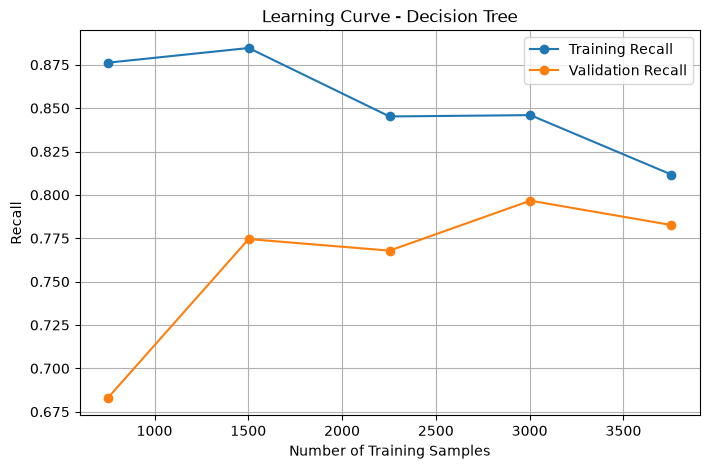

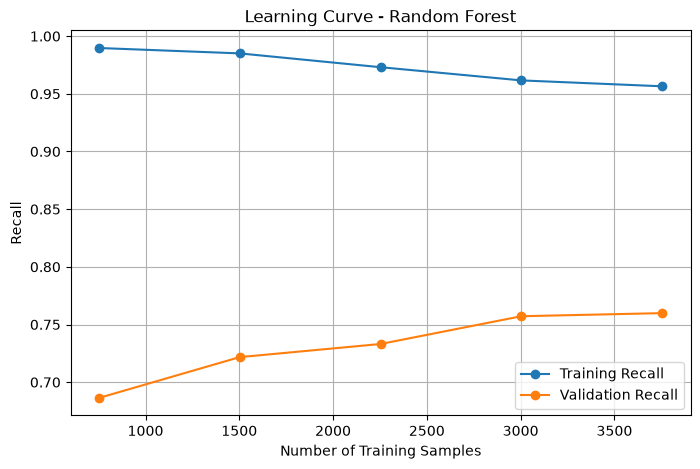

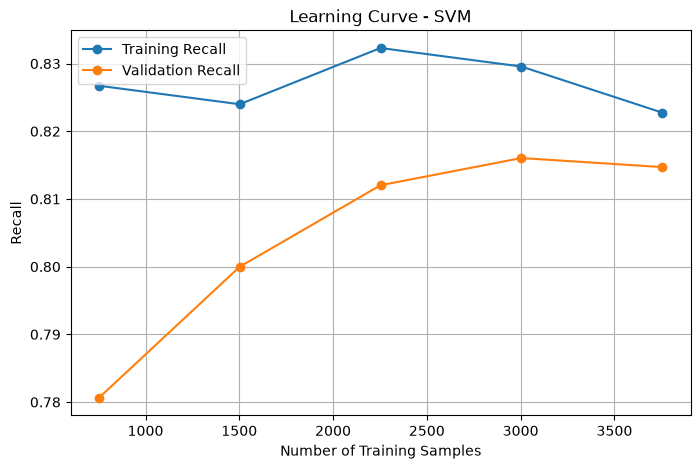

In [54]:

# Plot learning curves

for model_name, results in learning_curve_results.items():

    train_sizes = results["train_sizes"]
    train_mean = results["train_scores"].mean(axis=1)
    validation_mean = results["validation_scores"].mean(axis=1)

    plt.figure(figsize=(8, 5))

    plt.plot(train_sizes, train_mean, marker="o", label="Training Recall")
    plt.plot(train_sizes, validation_mean, marker="o", label="Validation Recall")

    plt.title(f"Learning Curve - {model_name}")
    plt.xlabel("Number of Training Samples")
    plt.ylabel("Recall")
    plt.legend()
    plt.grid(True)

    plt.show()



In [55]:
# Compare tuned models using cross-validation Recall

day3_comparison = pd.DataFrame({
    name: {
        "CV Recall": search.best_score_,
        "Best Parameters": str(search.best_params_)
    }
    for name, search in day3_searches.items()
}).T

print(day3_comparison)

              CV Recall                                    Best Parameters
Decision Tree  0.782617  {'classifier__max_depth': 5, 'classifier__min_...
Random Forest  0.759868  {'classifier__max_depth': 10, 'classifier__min...
SVM            0.814706  {'classifier__C': 1, 'classifier__gamma': 'auto'}


In [56]:
champion_name = max(
    day3_searches,
    key=lambda name: day3_searches[name].best_score_
)

champion_model = day3_best_models[champion_name]

print("Day 3 Champion:", champion_name)
print("Best CV Recall:",
      round(day3_searches[champion_name].best_score_, 4))

print("Best Parameters:",
      day3_searches[champion_name].best_params_)

Day 3 Champion: SVM
Best CV Recall: 0.8147
Best Parameters: {'classifier__C': 1, 'classifier__gamma': 'auto'}


In [57]:
import joblib
from pathlib import Path

model_path = Path("../models/churn_v3.joblib")

joblib.dump(champion_model, model_path)

print("Model saved:", model_path)


Model saved: ..\models\churn_v3.joblib


# Day 4

In [58]:

# DAY 4 - Feature Engineering

def engineer_features(data):

    data = data.copy()

    # 1. Group customer tenure
    data["tenure_group"] = pd.cut(
        data["tenure"],
        bins=[-1, 12, 24, 48, 72],
        labels=["0-12", "13-24", "25-48", "49-72"]
    ).astype("object")

    # 2. Average monthly spending
    data["avg_monthly_spend"] = (
        data["TotalCharges"] / (data["tenure"] + 1)
    )

    # 3. Contract flag
    data["is_month_to_month"] = (
        data["Contract"] == "Month-to-month"
    ).astype(int)

    # 4. Fiber internet flag
    data["has_fiber"] = (
        data["InternetService"] == "Fiber optic"
    ).astype(int)

    # 5. Electronic check flag
    data["is_electronic_check"] = (
        data["PaymentMethod"] == "Electronic check"
    ).astype(int)

    # 6. Online security flag
    data["has_online_security"] = (
        data["OnlineSecurity"] == "Yes"
    ).astype(int)

    return data


# Apply to training and testing data
X_train_fe = engineer_features(X_train)
X_test_fe = engineer_features(X_test)

print("Original features:", X_train.shape[1])
print("New features:", X_train_fe.shape[1])

print("\nNew feature columns:")
print(X_train_fe.columns[-6:].tolist())

print("\nSample engineered data:")
print(X_train_fe[
    [
        "tenure_group",
        "avg_monthly_spend",
        "is_month_to_month",
        "has_fiber",
        "is_electronic_check",
        "has_online_security"
    ]
].head())


Original features: 19
New features: 25

New feature columns:
['tenure_group', 'avg_monthly_spend', 'is_month_to_month', 'has_fiber', 'is_electronic_check', 'has_online_security']

Sample engineered data:
     tenure_group  avg_monthly_spend  is_month_to_month  has_fiber  \
3738        25-48          47.268056                  1          0   
3151        13-24          71.971875                  1          1   
4860        13-24          42.167857                  0          0   
3867        25-48          70.581481                  0          0   
3810         0-12          22.275000                  1          0   

      is_electronic_check  has_online_security  
3738                    1                    0  
3151                    0                    1  
4860                    0                    1  
3867                    0                    0  
3810                    1                    0  


In [59]:
from sklearn.feature_selection import SelectKBest, f_classif

In [60]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify numerical and categorical columns
num_cols_fe = X_train_fe.select_dtypes(
    include=["int64", "float64"]
).columns

cat_cols_fe = X_train_fe.select_dtypes(
    include=["object"]
).columns

# Numerical preprocessing
num_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
cat_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combined preprocessing
preprocessor_day4 = ColumnTransformer([
    ("num", num_transformer, num_cols_fe),
    ("cat", cat_transformer, cat_cols_fe)
])

print("Numerical features:", len(num_cols_fe))
print("Categorical features:", len(cat_cols_fe))

Numerical features: 9
Categorical features: 16


In [61]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

# Model A - All features
rf_all = Pipeline([
    ("preprocessor", preprocessor_day4),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=1
    ))
])

# Model B - Selected features
rf_selected = Pipeline([
    ("preprocessor", preprocessor_day4),
    ("selector", SelectKBest(
        score_func=f_classif,
        k=20
    )),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=1
    ))
])

# Evaluate both using cross-validation
all_scores = cross_val_score(
    rf_all, X_train_fe, y_train,
    scoring="recall",
    cv=cv_strategy,
    n_jobs=-1
)

selected_scores = cross_val_score(
    rf_selected, X_train_fe, y_train,
    scoring="recall",
    cv=cv_strategy,
    n_jobs=-1
)

print("All Features Recall:", all_scores.mean())
print("Selected Features Recall:", selected_scores.mean())


All Features Recall: 0.6387916395039074
Selected Features Recall: 0.663581513763806


In [62]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [63]:
from xgboost import XGBClassifier

In [64]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score

In [65]:
negative = (y_train == 0).sum()
positive = (y_train == 1).sum()

scale_pos_weight = negative / positive

print("Negative:", negative)
print("Positive:", positive)
print("Scale pos weight:", scale_pos_weight)

Negative: 4139
Positive: 1495
Scale pos weight: 2.768561872909699


In [66]:
rf_model = Pipeline([
    ("preprocessor", preprocessor_day4),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

In [67]:
xgb_model = Pipeline([
    ("preprocessor", preprocessor_day4),
    ("classifier", XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

In [68]:
rf_scores = cross_val_score(
    rf_model,
    X_train_fe,
    y_train,
    cv=cv_strategy,
    scoring="recall",
    n_jobs=-1
)

xgb_scores = cross_val_score(
    xgb_model,
    X_train_fe,
    y_train,
    cv=cv_strategy,
    scoring="recall",
    n_jobs=-1
)

print("Random Forest Recall:", rf_scores)
print("Random Forest Mean:", rf_scores.mean())

print("XGBoost Recall:", xgb_scores)
print("XGBoost Mean:", xgb_scores.mean())


Random Forest Recall: [0.70481928 0.71485944 0.71142285]
Random Forest Mean: 0.7103671868502736
XGBoost Recall: [0.79116466 0.7811245  0.78957916]
XGBoost Mean: 0.7872894383143798


In [69]:
# Train XGBoost on complete training data
xgb_model.fit(X_train_fe, y_train)

# Predictions
xgb_pred = xgb_model.predict(X_test_fe)

# Evaluate
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score
)

xgb_prob = xgb_model.predict_proba(X_test_fe)[:, 1]

xgb_test_results = {
    "Accuracy": accuracy_score(y_test, xgb_pred),
    "Precision": precision_score(y_test, xgb_pred),
    "Recall": recall_score(y_test, xgb_pred),
    "ROC-AUC": roc_auc_score(y_test, xgb_prob)
}

print("Day 4 XGBoost Test Results")

for metric, value in xgb_test_results.items():
    print(f"{metric}: {value:.4f}")

Day 4 XGBoost Test Results
Accuracy: 0.7601
Precision: 0.5323
Recall: 0.7941
ROC-AUC: 0.8423


In [70]:
import joblib
from pathlib import Path

# Create models directory if required
Path("../models").mkdir(exist_ok=True)

# Save complete pipeline
joblib.dump(
    xgb_model,
    "../models/churn_v4.joblib"
)

print("Day 4 XGBoost model saved successfully!")

Day 4 XGBoost model saved successfully!


# Day 5


In [71]:
import tensorflow as tf

# Load MNIST dataset
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Training labels:", y_train.shape)

Training data: (60000, 28, 28)
Testing data: (10000, 28, 28)
Training labels: (60000,)


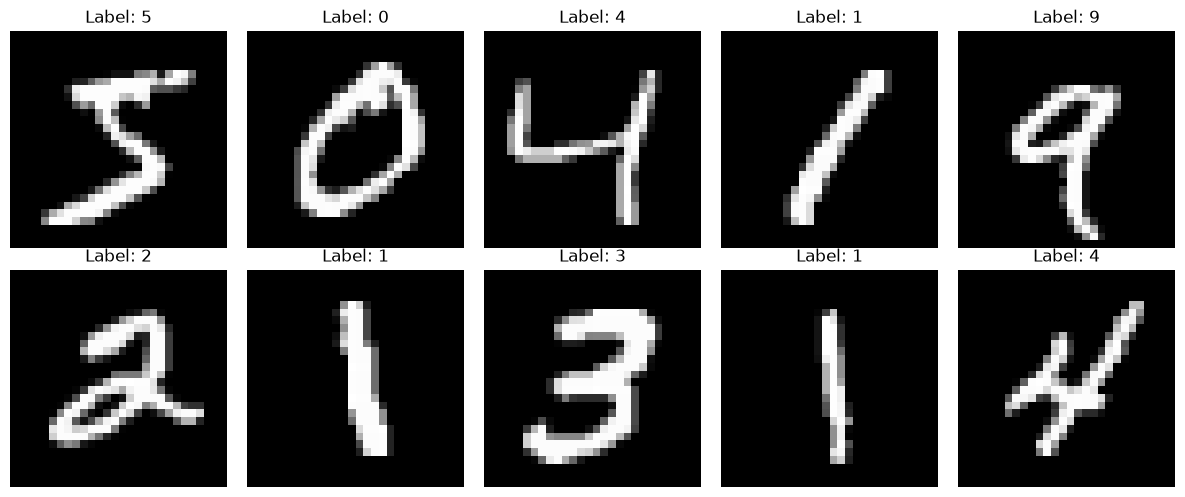

In [72]:
import matplotlib.pyplot as plt

# Display first 10 images
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [73]:
# Normalise pixel values
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("Training range:", X_train.min(), X_train.max())
print("Testing range:", X_test.min(), X_test.max())

Training range: 0.0 1.0
Testing range: 0.0 1.0


In [74]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense

# Create ANN
model = Sequential([
    Flatten(input_shape=(28, 28)),

    Dense(128, activation="relu"),

    Dense(64, activation="relu"),

    Dense(10, activation="softmax")
])

# Display architecture
model.summary()



C:\Users\pritd\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [75]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [76]:
history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.9256 - loss: 0.2551 - val_accuracy: 0.9705 - val_loss: 0.1023
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9681 - loss: 0.1048 - val_accuracy: 0.9752 - val_loss: 0.0817
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9766 - loss: 0.0736 - val_accuracy: 0.9757 - val_loss: 0.0812
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9826 - loss: 0.0545 - val_accuracy: 0.9760 - val_loss: 0.0811
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9857 - loss: 0.0431 - val_accuracy: 0.9763 - val_loss: 0.0929


In [77]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9772 - loss: 0.0839
Test Loss: 0.0839090570807457
Test Accuracy: 0.9771999716758728


In [78]:
import numpy as np

predictions = model.predict(X_test[:10])

predicted_labels = np.argmax(predictions, axis=1)

print("Predicted:", predicted_labels)
print("Actual:   ", y_test[:10])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step
Predicted: [7 2 1 0 4 1 4 9 5 9]
Actual:    [7 2 1 0 4 1 4 9 5 9]


In [81]:
# Restore Telco Churn dataset

X_churn = df.drop(columns=["Churn", "customerID"], errors="ignore")
y_churn = df["Churn"].map({"Yes": 1, "No": 0})

from sklearn.model_selection import train_test_split

X_churn_train, X_churn_test, y_churn_train, y_churn_test = train_test_split(
    X_churn,
    y_churn,
    test_size=0.2,
    random_state=42,
    stratify=y_churn
)

print(X_churn_train.shape)
print(X_churn_test.shape)

(5634, 19)
(1409, 19)


In [82]:
# Identify numerical and categorical columns
num_cols = X_churn_train.select_dtypes(include=["number"]).columns
cat_cols = X_churn_train.select_dtypes(include=["object", "category"]).columns

# Create preprocessor
preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

# Fit on training data and transform both datasets
X_train_nn = preprocessor.fit_transform(X_churn_train)
X_test_nn = preprocessor.transform(X_churn_test)

# Convert sparse matrices to dense arrays
if hasattr(X_train_nn, "toarray"):
    X_train_nn = X_train_nn.toarray()
    X_test_nn = X_test_nn.toarray()

print("Training shape:", X_train_nn.shape)
print("Testing shape:", X_test_nn.shape)

Training shape: (5634, 45)
Testing shape: (1409, 45)


In [83]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

churn_model = Sequential([
    Input(shape=(X_train_nn.shape[1],)),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(1, activation="sigmoid")
])

churn_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 64)             │         2,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,057 (19.75 KB)

 Trainable params: 5,057 (19.75 KB)

 Non-trainable params: 0 (0.00 B)

In [84]:
churn_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [86]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_churn = churn_model.fit(
    X_train_nn,
    y_churn_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop]
)


Epoch 1/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8121 - loss: 0.4038 - val_accuracy: 0.8004 - val_loss: 0.4374
Epoch 2/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8150 - loss: 0.3983 - val_accuracy: 0.7950 - val_loss: 0.4360
Epoch 3/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8174 - loss: 0.3954 - val_accuracy: 0.7959 - val_loss: 0.4399
Epoch 4/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8203 - loss: 0.3942 - val_accuracy: 0.7933 - val_loss: 0.4392
Epoch 5/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8207 - loss: 0.3902 - val_accuracy: 0.7968 - val_loss: 0.4364
Epoch 6/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8221 - loss: 0.3871 - val_accuracy: 0.7986 - val_loss: 0.4460
Epoch 7/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8241 - loss: 0.3854 - val_accuracy: 0.8021 - val_loss: 0.4411


In [87]:
test_loss, test_accuracy = churn_model.evaluate(
    X_test_nn,
    y_churn_test
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7928 - loss: 0.4257
Test Loss: 0.4256892800331116
Test Accuracy: 0.7927608489990234


In [88]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Predict probabilities
y_prob_nn = churn_model.predict(X_test_nn).ravel()

# Convert probabilities into classes
y_pred_nn = (y_prob_nn >= 0.5).astype(int)

print("Accuracy:", accuracy_score(y_churn_test, y_pred_nn))
print("Precision:", precision_score(y_churn_test, y_pred_nn))
print("Recall:", recall_score(y_churn_test, y_pred_nn))
print("F1 Score:", f1_score(y_churn_test, y_pred_nn))
print("ROC-AUC:", roc_auc_score(y_churn_test, y_prob_nn))

45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
Accuracy: 0.7927608232789212
Precision: 0.6220238095238095
Recall: 0.5588235294117647
F1 Score: 0.5887323943661972
ROC-AUC: 0.8384303391976027


In [89]:
import joblib
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Load previous SVM champion
svm_model = joblib.load("../models/churn_day2_champion.joblib")

# Predict using original churn DataFrame
y_pred_svm = svm_model.predict(X_churn_test)
y_prob_svm = svm_model.predict_proba(X_churn_test)[:, 1]

print("SVM Accuracy:", accuracy_score(y_churn_test, y_pred_svm))
print("SVM Precision:", precision_score(y_churn_test, y_pred_svm))
print("SVM Recall:", recall_score(y_churn_test, y_pred_svm))
print("SVM F1:", f1_score(y_churn_test, y_pred_svm))
print("SVM ROC-AUC:", roc_auc_score(y_churn_test, y_prob_svm))

SVM Accuracy: 0.7437899219304471
SVM Precision: 0.511504424778761
SVM Recall: 0.7727272727272727
SVM F1: 0.6155484558040468
SVM ROC-AUC: 0.8210648686352011


In [90]:
from pathlib import Path

model_path = Path("../models/churn_ann_day5.keras")
model_path.parent.mkdir(parents=True, exist_ok=True)

churn_model.save(model_path)

print("ANN model saved successfully!")

ANN model saved successfully!


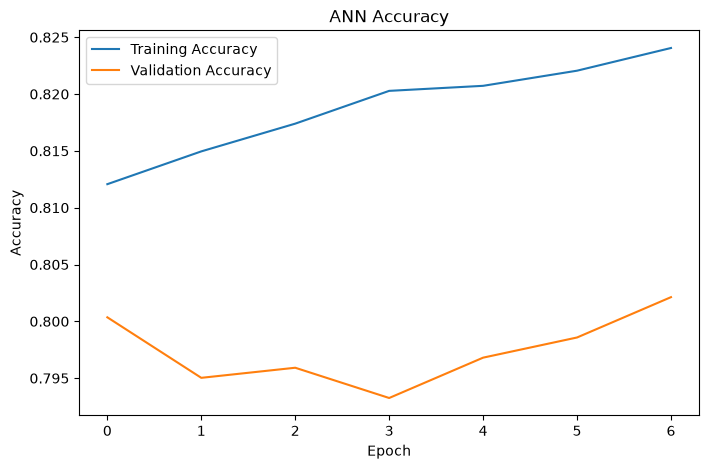

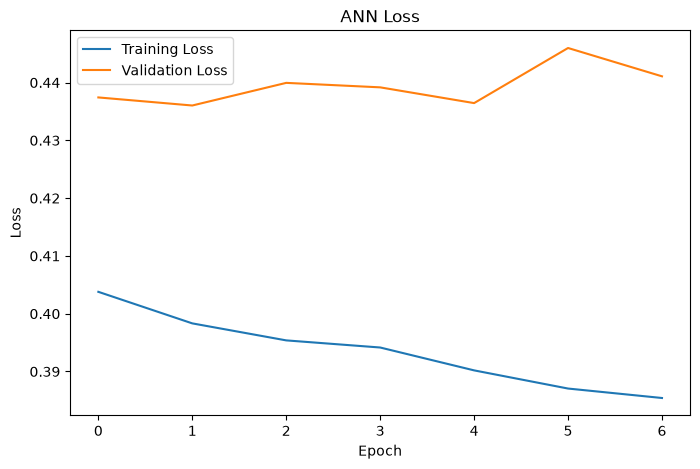

In [91]:
import matplotlib.pyplot as plt

# Accuracy graph
plt.figure(figsize=(8, 5))
plt.plot(history_churn.history["accuracy"], label="Training Accuracy")
plt.plot(history_churn.history["val_accuracy"], label="Validation Accuracy")
plt.title("ANN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# Loss graph
plt.figure(figsize=(8, 5))
plt.plot(history_churn.history["loss"], label="Training Loss")
plt.plot(history_churn.history["val_loss"], label="Validation Loss")
plt.title("ANN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [92]:
import pandas as pd

comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"],
    "SVM": [
        accuracy_score(y_churn_test, y_pred_svm),
        precision_score(y_churn_test, y_pred_svm),
        recall_score(y_churn_test, y_pred_svm),
        f1_score(y_churn_test, y_pred_svm),
        roc_auc_score(y_churn_test, y_prob_svm)
    ],
    "ANN": [
        accuracy_score(y_churn_test, y_pred_nn),
        precision_score(y_churn_test, y_pred_nn),
        recall_score(y_churn_test, y_pred_nn),
        f1_score(y_churn_test, y_pred_nn),
        roc_auc_score(y_churn_test, y_prob_nn)
    ]
})

print(comparison.round(4))

      Metric     SVM     ANN
0   Accuracy  0.7438  0.7928
1  Precision  0.5115  0.6220
2     Recall  0.7727  0.5588
3   F1 Score  0.6155  0.5887
4    ROC-AUC  0.8211  0.8384


In [93]:
import tensorflow as tf

(X_train_cnn, y_train_cnn), (X_test_cnn, y_test_cnn) = (
    tf.keras.datasets.fashion_mnist.load_data()
)

print("Training:", X_train_cnn.shape)
print("Testing:", X_test_cnn.shape)
print("Labels:", y_train_cnn.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training: (60000, 28, 28)
Testing: (10000, 28, 28)
Labels: (60000,)


# Day 6

In [5]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path("../myntradataset")

products = pd.read_csv(
    DATA_DIR / "styles.csv",
    engine="python",
    on_bad_lines="skip"
)

print("Dataset shape:", products.shape)
print("Columns:", products.columns.tolist())
print(products.head())

Dataset shape: (44424, 10)
Columns: ['id', 'gender', 'masterCategory', 'subCategory', 'articleType', 'baseColour', 'season', 'year', 'usage', 'productDisplayName']
      id gender masterCategory subCategory  articleType baseColour  season  \
0  15970    Men        Apparel     Topwear       Shirts  Navy Blue    Fall   
1  39386    Men        Apparel  Bottomwear        Jeans       Blue  Summer   
2  59263  Women    Accessories     Watches      Watches     Silver  Winter   
3  21379    Men        Apparel  Bottomwear  Track Pants      Black    Fall   
4  53759    Men        Apparel     Topwear      Tshirts       Grey  Summer   

     year   usage                             productDisplayName  
0  2011.0  Casual               Turtle Check Men Navy Blue Shirt  
1  2012.0  Casual             Peter England Men Party Blue Jeans  
2  2016.0  Casual                       Titan Women Silver Watch  
3  2011.0  Casual  Manchester United Men Solid Black Track Pants  
4  2012.0  Casual               

In [7]:
# Remove categories having fewer than 2 images
counts = products["masterCategory"].value_counts()

products = products[
    products["masterCategory"].isin(counts[counts >= 2].index)
].copy()

# Re-encode labels after filtering
encoder = LabelEncoder()
products["label"] = encoder.fit_transform(products["masterCategory"])

# Split dataset
train_df, test_df = train_test_split(
    products,
    test_size=0.2,
    random_state=42,
    stratify=products["label"]
)

print("Available images:", len(products))
print("Training:", len(train_df))
print("Testing:", len(test_df))
print("Categories:", list(encoder.classes_))

Available images: 44418
Training: 35534
Testing: 8884
Categories: ['Accessories', 'Apparel', 'Footwear', 'Free Items', 'Personal Care', 'Sporting Goods']


In [8]:
import tensorflow as tf

IMG_SIZE = (128, 128)
BATCH_SIZE = 32

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = image / 255.0
    return image, label

# Create TensorFlow datasets
train_ds = tf.data.Dataset.from_tensor_slices((
    train_df["image_path"].values,
    train_df["label"].values
))

test_ds = tf.data.Dataset.from_tensor_slices((
    test_df["image_path"].values,
    test_df["label"].values
))

train_ds = (
    train_ds
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    .shuffle(1000)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_ds = (
    test_ds
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("Image pipeline ready!")

Image pipeline ready!


In [9]:
from tensorflow.keras import layers, models

# Data augmentation
augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])

# CNN architecture
cnn_model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    augmentation,

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(128, activation="relu"),
    layers.Dense(len(encoder.classes_), activation="softmax")
])

cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,414 (12.61 MB)

 Trainable params: 3,305,414 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [11]:
from tensorflow.keras.callbacks import EarlyStopping

cnn_early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history_cnn = cnn_model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=10,
    callbacks=[cnn_early_stop]
)

Epoch 1/10


C:\Users\pritd\AppData\Roaming\Python\Python312\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1111/1111 ━━━━━━━━━━━━━━━━━━━━ 426s 378ms/step - accuracy: 0.8622 - loss: 0.3901 - val_accuracy: 0.9294 - val_loss: 0.2138
Epoch 2/10
1111/1111 ━━━━━━━━━━━━━━━━━━━━ 374s 336ms/step - accuracy: 0.9312 - loss: 0.2149 - val_accuracy: 0.9587 - val_loss: 0.1391
Epoch 3/10
1111/1111 ━━━━━━━━━━━━━━━━━━━━ 388s 349ms/step - accuracy: 0.9484 - loss: 0.1696 - val_accuracy: 0.9615 - val_loss: 0.1263
Epoch 4/10
1111/1111 ━━━━━━━━━━━━━━━━━━━━ 383s 344ms/step - accuracy: 0.9539 - loss: 0.1529 - val_accuracy: 0.9602 - val_loss: 0.1360
Epoch 5/10
1111/1111 ━━━━━━━━━━━━━━━━━━━━ 375s 337ms/step - accuracy: 0.9579 - loss: 0.1397 - val_accuracy: 0.9671 - val_loss: 0.1110
Epoch 6/10
1111/1111 ━━━━━━━━━━━━━━━━━━━━ 378s 340ms/step - accuracy: 0.9634 - loss: 0.1235 - val_accuracy: 0.9701 - val_loss: 0.1077
Epoch 7/10
1111/1111 ━━━━━━━━━━━━━━━━━━━━ 385s 346ms/step - accuracy: 0.9646 - loss: 0.1163 - val_accuracy: 0.9751 - val_loss: 0.0914
Epoch 8/10
1111/1111 ━━━━━━━━━━━━━━━━━━━━ 384s 345ms/step - accuracy: 0.9

In [12]:
test_loss, test_accuracy = cnn_model.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

278/278 ━━━━━━━━━━━━━━━━━━━━ 26s 94ms/step - accuracy: 0.9781 - loss: 0.0808
Test Loss: 0.08081621676683426
Test Accuracy: 0.9780504107475281


In [13]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_pred = np.argmax(cnn_model.predict(test_ds), axis=1)

print(classification_report(
    y_true, y_pred,
    target_names=encoder.classes_
))

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))

278/278 ━━━━━━━━━━━━━━━━━━━━ 25s 88ms/step
                precision    recall  f1-score   support

   Accessories       0.96      0.97      0.96      2255
       Apparel       0.99      0.99      0.99      4278
      Footwear       0.99      0.99      0.99      1844
    Free Items       0.00      0.00      0.00        21
 Personal Care       0.94      0.94      0.94       481
Sporting Goods       0.60      0.60      0.60         5

      accuracy                           0.98      8884
     macro avg       0.75      0.75      0.75      8884
  weighted avg       0.98      0.98      0.98      8884

Confusion Matrix:
[[2183   45    9    0   18    0]
 [  41 4228    1    0    7    1]
 [  19    1 1823    0    1    0]
 [  18    3    0    0    0    0]
 [  23    5    0    0  452    1]
 [   0    0    0    0    2    3]]


c:\python312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\python312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\python312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [14]:
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(exist_ok=True)

cnn_model.save(MODEL_DIR / "retail_cnn_day6.keras")

print("CNN model saved successfully!")

CNN model saved successfully!
